# Day 33 | Choose What Search Returns

**KGP Talkie**

Compare top-k, score filtering, MMR, and a saved index.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

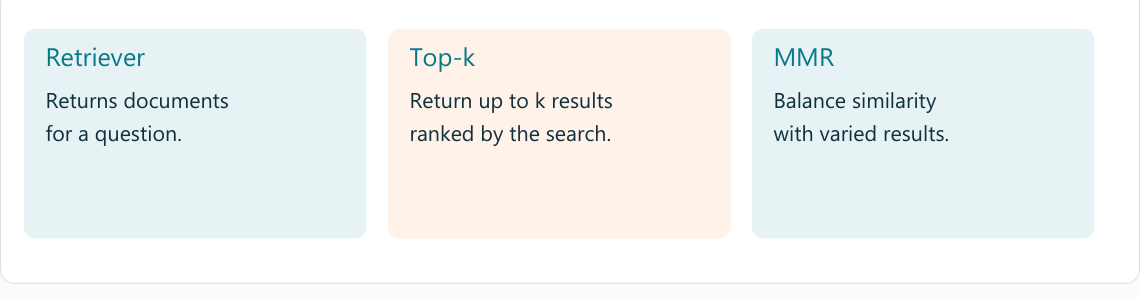

Document keeps text and source details. OllamaEmbeddings returns vectors, not chat replies.

In [5]:
from langchain_core.documents import Document
from langchain_ollama import OllamaEmbeddings

FAISS stores vectors and finds nearby vectors. Its result is linked back to source text.

In [6]:
from langchain_community.vectorstores import FAISS

One fact per line keeps the first search example easy to inspect.

In [7]:
lines = (ASSETS / "course-notes.txt").read_text(encoding="utf-8").splitlines()

enumerate gives a line position. The list creates one Document per line and keeps an evidence label.

In [8]:
docs = [Document(page_content=line, metadata={"source": "course-notes.txt", "line": i + 1}) for i, line in enumerate(lines)]

Use the same downloaded embedding model for stored facts and questions.

In [9]:
embeddings = OllamaEmbeddings(model="nomic-embed-text", base_url="http://localhost:11434")

Embed each document and build this notebook's own index. No previous day is required.

In [10]:
store = FAISS.from_documents(docs, embeddings)

In [11]:
similarity = store.as_retriever(search_kwargs={"k": 2})

In [12]:
[(doc.page_content, doc.metadata) for doc in similarity.invoke("Class time and laptop requirements")]

[('Bring a laptop to both classes.',
  {'source': 'course-notes.txt', 'line': 3}),
 ('Python class is on Monday at 10:00 in Room 2.',
  {'source': 'course-notes.txt', 'line': 1})]

MMR chooses two items from four candidates and favors useful variety. These small numbers fit our four facts.

In [13]:
mmr = store.as_retriever(search_type="mmr", search_kwargs={"k": 2, "fetch_k": 4})

In [14]:
[(doc.page_content, doc.metadata) for doc in mmr.invoke("Class time and laptop requirements")]

[('Bring a laptop to both classes.',
  {'source': 'course-notes.txt', 'line': 3}),
 ('Pandas class is on Tuesday at 11:00 in Room 3.',
  {'source': 'course-notes.txt', 'line': 2})]

These are distance scores from this FAISS configuration. Smaller distance means closer here, not a universal confidence score.

In [15]:
store.similarity_search_with_score("When is Python?", k=2)

[(Document(id='36e5a985-facc-4c0b-ad30-c030e4021803', metadata={'source': 'course-notes.txt', 'line': 1}, page_content='Python class is on Monday at 10:00 in Room 2.'),
  np.float32(0.57773733)),
 (Document(id='26000371-3ed6-4ea6-94d6-cd5f3640d95f', metadata={'source': 'course-notes.txt', 'line': 2}, page_content='Pandas class is on Tuesday at 11:00 in Room 3.'),
  np.float32(0.9891262))]

In [16]:
store.save_local(str(OUTPUT / "own-index"))

This reads only the bundle we created just above. Never set this flag for an untrusted downloaded pickle.

In [17]:
reopened = FAISS.load_local(str(OUTPUT / "own-index"), embeddings, allow_dangerous_deserialization=True)

In [18]:
[doc.page_content for doc in reopened.similarity_search("What should I bring?", k=2)]

['Bring a laptop to both classes.',
 'Pandas class is on Tuesday at 11:00 in Room 3.']

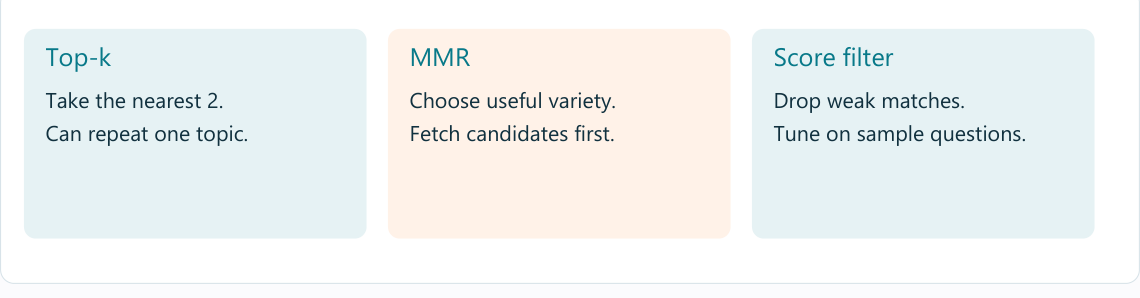

## Try a fresh input

Save an index you made, reload it, and repeat the query. Rebuild when the document or embedding model changes.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-vector-stores).